## Preliminaries

Visualize heatmaps of different xai methods from `tf-explain` and `iNNvestigate`.

In [1]:
!pwd
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server

import sys
sys.path.append('./tf-explain/')
sys.path.append('./Quantus/Quantus/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

from tf_explain.core.vanilla_gradients import VanillaGradients
from tf_explain.core.gradients_inputs import GradientsInputs
from tf_explain.core.smoothgrad import SmoothGrad
from tf_explain.core.integrated_gradients import IntegratedGradients

from innvestigate.innvestigate.analyzer import gradient_based as G # GBP, Deconvnet
from innvestigate.innvestigate.analyzer.relevance_based import relevance_analyzer as RA # LRP

In [3]:
use_mini_dataset   = True
compress_B_lucorum = True
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
MASKS_PATH = metafolder + dataset_folder + 'masks.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/saliency/'

/home/tchiaburu/anaconda3/envs/tf2_gpu/lib/python3.9/site-packages/ipykernel/ipkernel.py:287: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


## Load images

In [4]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [5]:
batch_size = 64
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [6]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees_Christian/


In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image_and_mask(file_id, img_lookup, img_width, img_height,
                                                                  BEES_PATH, BEES_PATH[:-1] + '_masks/Whole/'),
                                          label)

In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: ((normalization_layer(x[0]), x[1]), y))

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


In [9]:
for image_mask_batch, labels_batch in test_set.take(1):
    print(image_mask_batch[0].shape)
    print(image_mask_batch[1].shape)
    print(labels_batch[0])

(64, 224, 224, 3)
(64, 224, 224, 1)
tf.Tensor(0, shape=(), dtype=uint8)


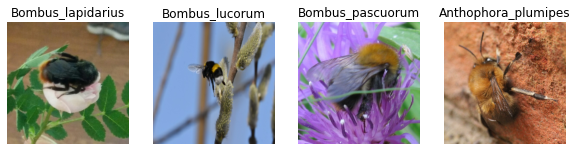

In [10]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[0][i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## XAI

In [11]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4

constructor, out_shape =  wm.build_simple_classifier, len(classes)

loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [12]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

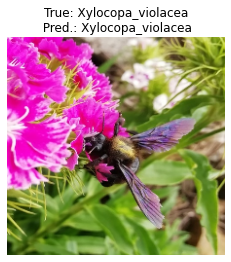

In [13]:
# Pick a correctly predicted image
counts, max_it = 0, 8 # how many hits to find
for img_mask, y_true in test_set.unbatch():
    # Predict class of example
    img, mask = img_mask
    y_pred = np.argmax(model.predict(np.expand_dims(img, axis = 0)))

    if y_pred == y_true:
        counts += 1
        if counts == max_it: break

plt.imshow(img)
plt.title('True: ' + classes[y_true] + '\n Pred.: ' + classes[y_pred])
plt.axis('off')
plt.show()

### tf-explain

In [14]:
# Compute explanation w.r.t. true or predicted class
explain_true = False # True = explain w.r.t. true label, False = w.r.t. predicted label
maps = []
te_maps = {}
explainers = [VanillaGradients(), GradientsInputs(), IntegratedGradients(), SmoothGrad()]
expl_names = ['Gradient', 'InputXGradient', 'IntegratedGradients', 'SmoothGrad']

for e, n in zip(explainers, expl_names):
    hm = e.explain((np.array([img]), None), model, y_true if explain_true else y_pred, norm = "min_max")

    te_maps[n] = hm
maps.append(te_maps)

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


### iNNvestigate

In [15]:
# Strip model of the softmax layer
# Note: For multi-output models cut off layers not responsible for species classif.
model_no_soft = tf.keras.models.Model(model.input, model.layers[-2].output)
model_no_soft.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
jpg (InputLayer)             [(None, 224, 224, 3)]     0         
_________________________________________________________________
CNN_Blocks_ResNet50_iNat_raw (None, 2048)              23561152  
_________________________________________________________________
dense_species (Dense)        (None, 22)                45078     
Total params: 23,606,230
Trainable params: 23,553,110
Non-trainable params: 53,120
_________________________________________________________________


In [16]:
inn_maps = {}
analyzers = [G.GuidedBackprop(model_no_soft), G.Deconvnet(model_no_soft),
             RA.LRPEpsilon(model_no_soft), RA.LRPGamma(model_no_soft)]
ana_names = ['Guided Backprop', 'Deconvnet', 'LRP Epsilon', 'LRP Gamma']


for a, n in zip(analyzers, ana_names):
    analysis = a.analyze(np.expand_dims(img, axis=0)) # max activation (not working w.r.t. to pred.)

    hm = list(analysis.values())[0] # heatmap is the first and only value of the analysis dictionary
    hm = tf.math.abs(hm)
    hm = np.max(hm, axis=-1)[0] # max along each RGB channel

    # Normalize to range between 0 and 1
    arr_min, arr_max  = np.min(hm), np.max(hm)
    hm = (hm - arr_min) / (arr_max - arr_min + 1e-16)

    inn_maps[n] = hm
maps.append(inn_maps)

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `

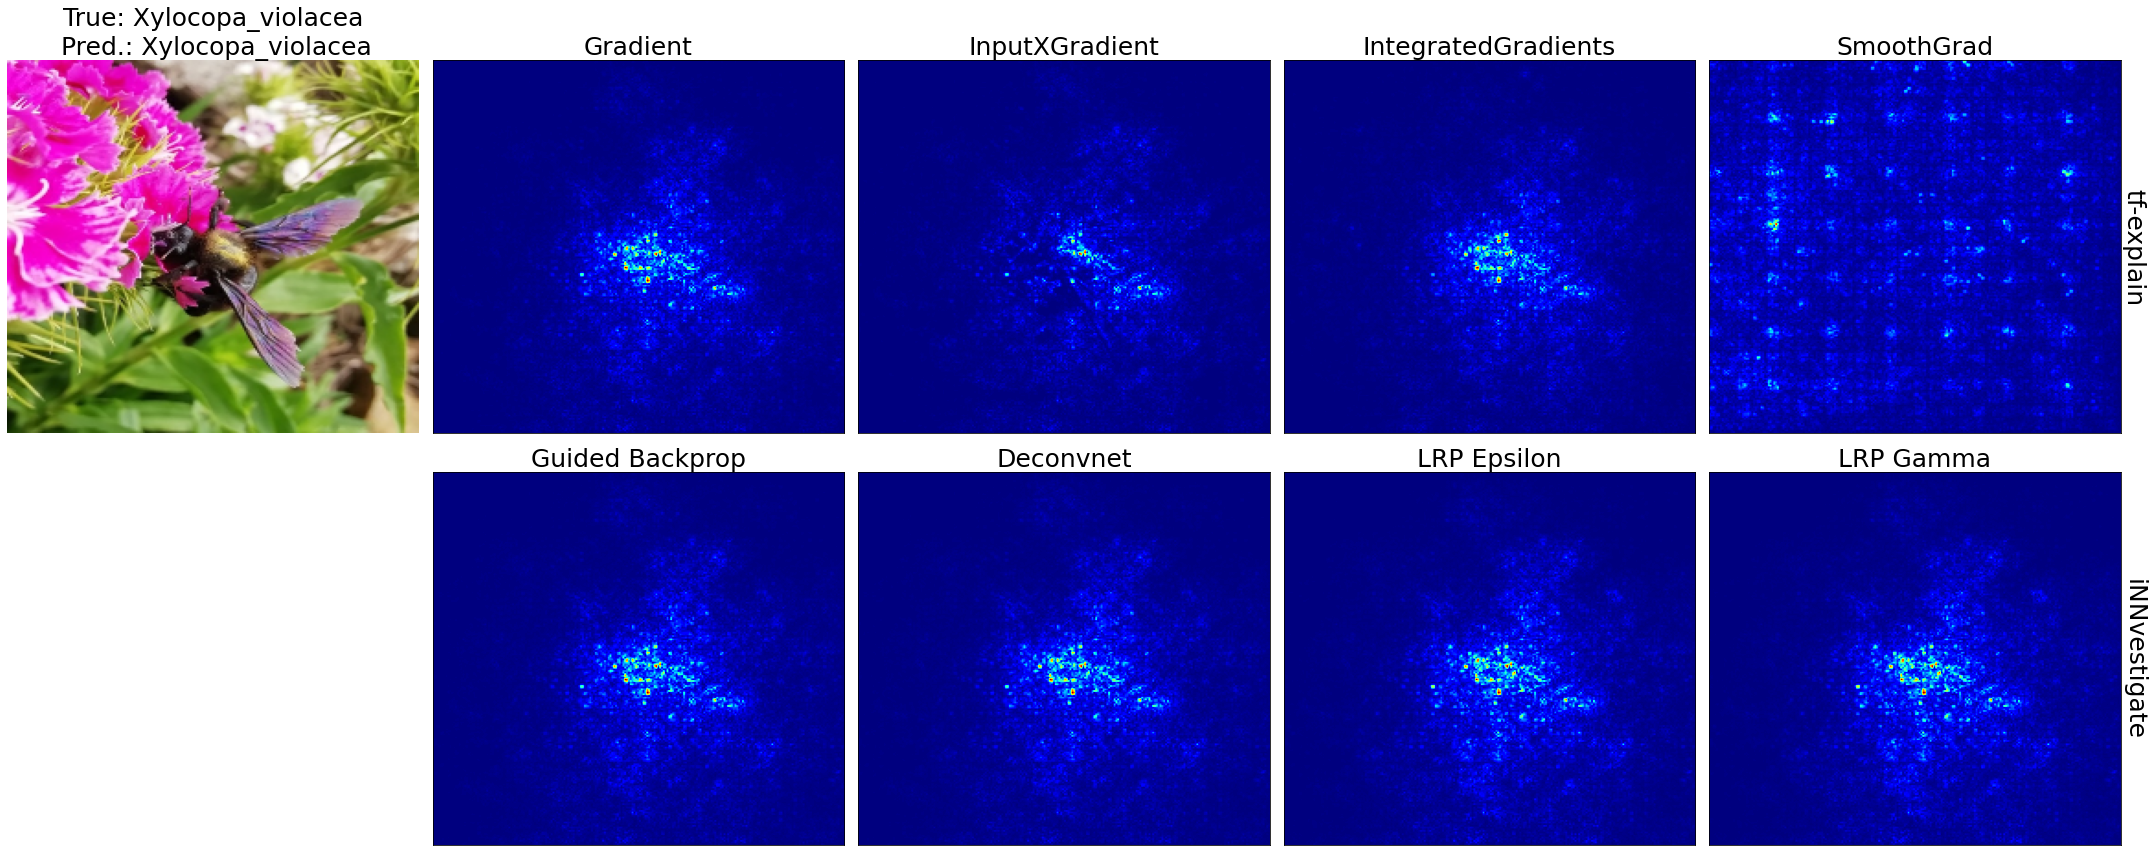

In [17]:
# Plot the example along with the saliency maps
num_rows, num_cols = 2, 5
libraries = ['tf-explain', 'iNNvestigate']
fsize = 25
plt.figure(figsize=(5 * (num_cols+1), 6 * num_rows))

plt.subplot(num_rows, num_cols, 1)
plt.imshow(img, aspect = 'auto')
plt.title('True: ' + classes[y_true] + '\n Pred.: ' + classes[y_pred], fontsize = fsize)
plt.axis('off')

for j in range(num_rows):
    for i in range(len(explainers)):
        ax = plt.subplot(num_rows, num_cols, i+j*num_cols+2)
        plt.imshow(list(maps[j].values())[i], cmap="jet", aspect = 'auto')
        plt.title(list(maps[j].keys())[i], fontsize = fsize)
        plt.xticks([], [])
        plt.yticks([], [])
        if i == len(explainers)-1:
            ax.yaxis.set_label_position("right")
            ax.set_ylabel(libraries[j], fontsize = fsize, rotation = -90, labelpad = 25)

plt.tight_layout()
plt.savefig(FIGURES_PATH + model_name + '_' + classes[y_true] + '_sal.jpg', bbox_inches='tight')
plt.show()